<a href="https://colab.research.google.com/github/frandresst-wq/Proyecto-de-Ciencia-de-Datos/blob/main/S4_Entrega3_SOTO_FRANCO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Este código oculta los mensajes de advertencia de la biblioteca jupyter_client

import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message=r".*datetime\.datetime\.utcnow\(\).*"
)

# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_explorado.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | _(Franco Soto Soto)_ |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20264
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# En Google Colab, mlxtend ya viene instalado. En local:
# !pip install mlxtend scikit-learn
print('Listo')

Listo


---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [4]:
df = pd.read_csv(RUTA + 'S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

Líneas: 21494 · Transacciones: 4000 · Productos: 21


,transaccion_id,fecha,tienda,producto
0,T00001,2025-03-02,Norte,pan
1,T00001,2025-03-02,Norte,vino
2,T00002,2025-06-22,Oriente,azucar
3,T00002,2025-06-22,Oriente,cafe
4,T00002,2025-06-22,Oriente,fideos


### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

++++++++ Lo siguiente transforma la columna producto en una cuadrícula (matriz) indicando True o False cuando esté ese producto en la transacción o cuando no esté, respectivamente.\
Esta matriz nos servirá para aplicarle Minería de datos, especialmente para descubrir reglas de asociación mediante el **algoritmo Apriori** (algoritmo que permite descubrir conjuntos de elementos que aparecen frecuentemente juntos en un conjunto de transacciones. Se utiliza principalmente para encontrar reglas de asociación, por ejemplo, identificar qué productos suelen comprarse juntos en un supermercado.)

In [ ]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]
#cesta

Matriz: (4000, 21)


producto,arroz,azucar,cafe,cerveza,detergente,fideos
transaccion_id,,,,,,
T00001,False,False,False,False,False,False
T00002,False,True,True,False,False,True
T00003,False,True,False,True,False,False
T00004,True,False,False,False,False,False
T00005,False,True,False,False,False,False


In [ ]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(30).round(3)

,0
producto,
pan,0.622
leche,0.566
palta,0.462
azucar,0.321
salsa de tomate,0.304
huevos,0.294
jamon,0.240
arroz,0.238
papas fritas,0.236


«pan» aparece en el 62 % de las canastas y «leche» en el 57 %. **Retén ese dato**: explica lo que viene a continuación.

### 1.2 Extraer las reglas

++++++++++  El siguiente código utiliza el algoritmo Apriori para descubrir qué productos se compran juntos y generar reglas de asociación. Después filtra las reglas para conservar solamente aquellas que relacionan un producto con otro.\
Cada regla tiene dos componentes:
- Antecedents (antecedentes): productos que aparecen antes de la flecha.
- Consequents (consecuentes): productos que aparecen después de la flecha.\
A -> B\
Por ejemplo:\
Pan -> Leche

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True)
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10)

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0]))
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 205


++++++++ Las Reglas de Asociación tienen 3 métricas:
- Soporte (Support): Que tan frecuente es cada relación de productos respecto al total de transacciones.
- Confianza (Confidence): Probabilidad que un cliente compre B dado que tiene A.
- Elevación (Lift): Mide fuerza de la regla. Un Lift>1 significa que la compra de ambos productos está verdaderamente asociada y no ocurre por pura casualidad.

### 1.3 La trampa: ordenar por confianza

In [ ]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
157,palta → pan,0.392,0.850,1.368
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
69,cerveza → papas fritas,0.098,0.667,2.830
75,detergente → pan,0.079,0.656,1.056
186,tomate → pan,0.133,0.645,1.038
57,cafe → pan,0.127,0.643,1.035
183,queso → pan,0.144,0.637,1.024


Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

++++++++++
Este ejemplo demuestra por qué una confianza alta no significa necesariamente que exista una asociación importante entre dos productos. Para interpretar correctamente una regla de asociación debemos analizar tanto la confianza como el lift.\
Esto demuestra que comprar detergente aporta muy poca información adicional sobre la compra de pan.

### 1.4 El mismo cálculo, ordenado por lift

In [ ]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
68,papas fritas → cerveza,0.098,0.415,2.830
69,cerveza → papas fritas,0.098,0.667,2.830
202,queso → vino,0.064,0.280,2.743
201,vino → queso,0.064,0.623,2.743
88,salsa de tomate → fideos,0.172,0.566,2.573
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
21,azucar → cafe,0.147,0.458,2.327


Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

In [ ]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

pan → leche     soporte 0.344 · confianza 0.554 · lift 0.979
leche → pan     soporte 0.344 · confianza 0.608 · lift 0.979


`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

+++++++   Este ejemplo muestra una de las ideas más importantes de las reglas de asociación en minería de datos: una confianza alta no garantiza que una regla sea útil.\
Etapa -	Métrica	- ¿Para qué sirve?\
Filtrar	- Soporte	- Eliminar combinaciones demasiado poco frecuentes.\
Ordenar	- Lift	- Priorizar asociaciones positivas más fuertes.\
Interpretar -	Confianza -	Describir qué proporción de compradores de A también compra B.

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(
    cesta,
    min_support=0.05,
    use_colnames=True
)

reglas = association_rules(
    frecuentes,
    metric='confidence',
    min_threshold=0.10
)

print("Total de reglas:", len(reglas))

print("Reglas con 2 antecedentes:",
      (reglas['antecedents'].apply(len) == 2).sum())

Total de reglas: 682
Reglas con 2 antecedentes: 243


In [ ]:
reglas_dobles = reglas[
    (reglas['antecedents'].apply(len) == 2) &
    (reglas['consequents'].apply(len) == 1)
]

top3 = reglas_dobles.nlargest(3, 'lift')

display(top3[
    ['antecedents', 'consequents',
     'support', 'confidence', 'lift']
])

,antecedents,consequents,support,confidence,lift
312,"(papas fritas, pan)",(cerveza),0.06075,0.429329,2.930571
302,"(papas fritas, leche)",(cerveza),0.05725,0.424861,2.900074
303,"(leche, cerveza)",(papas fritas),0.05725,0.681548,2.890976


+++++\
Las tres reglas dobles muestran que la combinación de dos productos permite identificar patrones de compra más específicos que los obtenidos con reglas simples.

Interpretación de las tres reglas

Primera regla: El 42,93 % de las transacciones que contienen papas fritas y pan también incluyen cerveza. Su lift de 2,93 indica que la cerveza aparece casi tres veces más frecuentemente de lo esperado según su frecuencia general.

Segunda regla: El 42,49 % de quienes compran papas fritas y leche también compran cerveza. Su lift de 2,90 indica una asociación positiva importante.

Tercera regla: El 68,15 % de las transacciones que contienen leche y cerveza también incluyen papas fritas. Su lift de 2,89 muestra una asociación positiva fuerte.

**¿Qué aportan respecto de las reglas simples?**\
Las reglas simples analizan asociaciones entre dos productos:\
{Papas fritas}->{Cerveza}

Las reglas dobles permiten analizar asociaciones condicionadas a la presencia de otro producto:

{Papas fritas,Pan}->{Cerveza}


Esto permite descubrir si la presencia de un segundo producto aumenta o disminuye la confianza de una asociación.

Sin embargo, para afirmar que la regla doble aporta una asociación más fuerte, debemos comparar sus valores de confianza y lift con los de las reglas simples correspondientes.

In [ ]:
comparacion = reglas[
    (reglas['consequents'] == frozenset({'cerveza'})) &
    (reglas['antecedents'].isin([
        frozenset({'papas fritas'}),
        frozenset({'pan'}),
        frozenset({'papas fritas', 'pan'})
    ]))
]

display(comparacion[
    ['antecedents', 'consequents',
     'support', 'confidence', 'lift']
])

,antecedents,consequents,support,confidence,lift
66,(pan),(cerveza),0.09325,0.149980,1.023754
68,(papas fritas),(cerveza),0.09775,0.414634,2.830267
312,"(papas fritas, pan)",(cerveza),0.06075,0.429329,2.930571


¿Qué descubrimos?
Primero: el pan prácticamente no aporta información por sí solo.

La regla Pan → Cerveza tiene un lift de 1,02, muy cercano a 1. Esto indica que comprar pan prácticamente no modifica la probabilidad de comprar cerveza.

Segundo: las papas fritas tienen una asociación fuerte con la cerveza.

La regla Papas fritas → Cerveza tiene una confianza de 41,46 % y un lift de 2,83.

Tercero: agregar pan mejora muy poco la asociación.

Al combinar papas fritas y pan:
- La confianza aumenta de 41,46 % a 42,93 %: apenas 1,47 puntos porcentuales.
- El lift aumenta de 2,83 a 2,93.
- El soporte disminuye de 9,78 % a 6,08 %.
3. ¿La regla doble aporta algo nuevo?
Aporta muy poca información adicional.

La asociación con la cerveza está explicada principalmente por la presencia de papas fritas, no por agregar pan.

Aunque la regla doble tiene un lift ligeramente mayor, la mejora es pequeña y se aplica a menos transacciones.

La enseñanza principal:\
Una regla doble puede tener un lift alto, pero eso no significa necesariamente que descubra una asociación nueva. Siempre conviene compararla con las reglas simples para evaluar su aporte real.

---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [ ]:
grande = pd.read_csv(RUTA + 'S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'])
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(5)

Filas: 280,800 · Medidores: 260


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
0,M00000,2025-04-01,Hualpén,BT1,0.985,3.1,0
1,M00001,2025-04-01,Los Ángeles,BT1,0.362,3.1,0
2,M00002,2025-04-01,Hualpén,BT1,0.371,3.1,0
3,M00003,2025-04-01,Talcahuano,BT1,1.200,3.1,0
4,M00004,2025-04-01,San Pedro de la Paz,BT1,0.292,3.1,0


In [ ]:
#Este código entrega tipos de datos y fechas extremas
print(grande.dtypes)
print('Menor fecha:',grande['fecha_hora'].min())
print('Mayor fecha:',grande['fecha_hora'].max())

medidor_id               object
fecha_hora       datetime64[ns]
comuna                   object
tarifa                   object
consumo_kwh             float64
temperatura_c           float64
hora                      int32
dtype: object
Menor fecha: 2025-04-01 00:00:00
Mayor fecha: 2025-06-29 22:00:00


### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

+++++++++\
El siguiente código construye un perfil de consumo eléctrico para cada medidor, calculando cuatro características (consumo_medio=promedio de consumo eléctrico de cada medidor, variabilidad=desviación estándar del consumo de cada medidor, punta=percentil 95 del consumo de cada medidor, o sea, aproximadamente el 95 % de sus registros tiene un consumo igual o inferior a ese valor y razon_nocturna=consumo promedio de cada medidor considerando solamente los registros correspondientes a las horas 0, 2 y 4 divididos por el consumo promedio general) que posteriormente pueden utilizarse para aplicar algoritmos de segmentación como K-means y detectar patrones de consumo o anomalías.

¿Qué significa el percentil 95, para poder calcular punta?

Si un medidor tiene 100 mediciones, el percentil 95 representa un nivel de consumo que aproximadamente 95 mediciones no superan, mientras que unas 5 lo superan.

Es útil para identificar niveles de consumo elevados sin depender exclusivamente del máximo absoluto.


In [ ]:
perfil = grande.groupby('medidor_id').agg(
    consumo_medio=('consumo_kwh', 'mean'),
    variabilidad=('consumo_kwh', 'std'),
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

Perfiles: (260, 4)


,consumo_medio,variabilidad,punta,razon_nocturna
count,260.000,260.000,260.000,260.000
mean,1.241,0.538,2.250,0.637
std,0.650,0.282,1.179,0.009
min,0.230,0.097,0.412,0.610
25%,0.829,0.357,1.510,0.632
50%,1.082,0.469,1.959,0.637
75%,1.520,0.656,2.737,0.642
max,4.327,1.883,7.953,0.661


### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

++++\
La estandarización transforma las variables para que tengan una escala comparable. Esto es especialmente importante en algoritmos como K-means, que utilizan distancias para agrupar observaciones.

En este conjunto de datos tienes cuatro variables con escalas diferentes: \
Variable - Mínimo - Máximo\
consumo_medio - 0.230	- 4.327\
variabilidad	- 0.097	- 1.883\
punta -	0.412 -	7.953\
razon_nocturna -	0.610 -	0.661

In [ ]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0. -0. -0.  0.]
Desviación de cada columna            : [1. 1. 1. 1.]


+++++++\
se creo una matriz X, estandarizada, para continuar con ella.\
El dataframe perfil no se ha modificado.

### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.506  inercia=   562.8  tamaños=[ 44 216]
k=3  silueta=0.339  inercia=   409.3  tamaños=[132  98  30]
k=4  silueta=0.335  inercia=   306.2  tamaños=[73 96 14 77]
k=5  silueta=0.336  inercia=   240.0  tamaños=[44 70  9 71 66]
k=6  silueta=0.342  inercia=   197.4  tamaños=[44 54 31  7 46 78]
k=7  silueta=0.343  inercia=   165.5  tamaños=[45  7 67 35 21 40 45]


La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

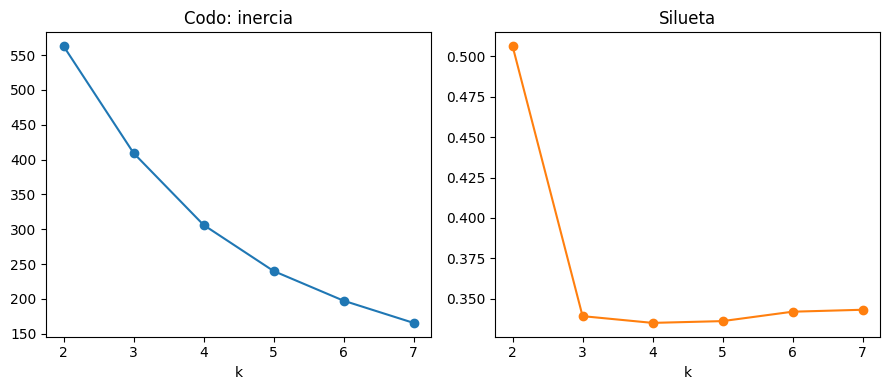

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

++++++ Esto sugiere que los medidores presentan una separación más clara cuando se organizan en dos grupos.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [ ]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

,consumo_medio,variabilidad,punta,razon_nocturna
grupo,,,,
0,0.782,0.339,1.418,0.638
1,1.442,0.626,2.614,0.636
2,2.606,1.131,4.719,0.639



Tamaño de cada grupo:
grupo
0    132
1     98
2     30


++++++++\
Este código aplica K-means con 3 grupos (k = 3) para segmentar los 260 medidores eléctricos según sus características de consumo.\
Esto significa que k = 2 produce grupos mejor separados según la silueta.\
Sin embargo, k = 3 permite identificar tres niveles de consumo, lo que puede ser más útil desde una perspectiva de análisis operativo, usando los resultados para identificar tres perfiles claramente diferenciados por su nivel de consumo: bajo, medio y alto.

### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

+++++\
**Consumo bajo y estable** (ya que tiene bajo consumo promedio, poca variabilidad y puntas reducidas)

**Consumo moderado y variable**  (ya que tienen consumo intermedio, con fluctuaciones y puntas moderadas)

**Consumo alto y fluctuante**  (ya que tienen consumo elevado, mayor variabilidad y puntas de demanda altas)

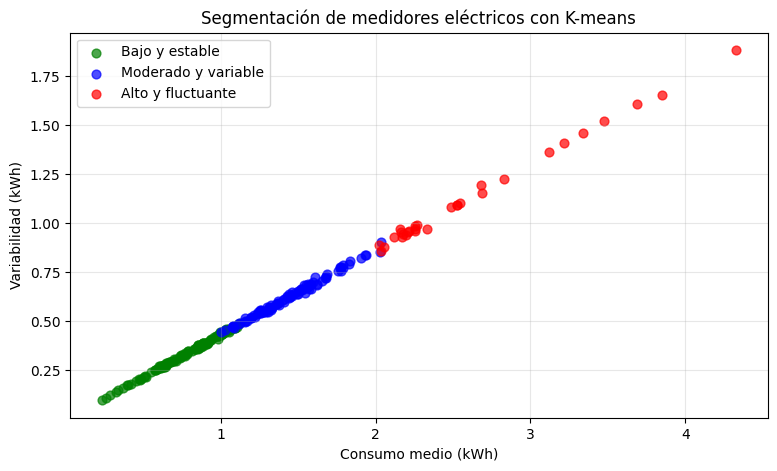

In [ ]:
#Gráfico de segmentación (grupos)
import matplotlib.pyplot as plt

nombres = {
    0: 'Bajo y estable',
    1: 'Moderado y variable',
    2: 'Alto y fluctuante'
}

colores = ['green', 'blue', 'red']

plt.figure(figsize=(9, 5))

for grupo in sorted(perfil['grupo'].unique()):
    datos = perfil[perfil['grupo'] == grupo]

    plt.scatter(
        datos['consumo_medio'],
        datos['variabilidad'],
        color=colores[grupo],
        label=nombres[grupo],
        alpha=0.7,
        s=40
    )

plt.xlabel('Consumo medio (kWh)')
plt.ylabel('Variabilidad (kWh)')
plt.title('Segmentación de medidores eléctricos con K-means')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

++++++++++\
Este código permite detectar medidores de consumo eléctrico con comportamientos anómalos, utilizando los grupos obtenidos previamente mediante K-Means.

La idea es identificar aquellos medidores que están demasiado alejados del comportamiento típico de su propio grupo.\
Establece como umbral el percentil 97 de las distancias. Esto significa que aproximadamente el 97 % de los medidores tiene una distancia menor o igual al umbral, y selecciona los medidores cuya distancia supera ese límite.

In [ ]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 97): 2.49
Medidores anómalos: 8 de 260


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,2,4.803
M00074,3.852,1.656,6.983,0.636,2,3.319
M00028,1.002,0.447,1.819,0.610,1,3.187
M00191,3.689,1.606,6.779,0.641,2,2.956
M00041,3.215,1.407,5.848,0.619,2,2.908
M00050,0.744,0.327,1.347,0.614,0,2.864
M00008,0.602,0.262,1.080,0.661,0,2.724
M00097,3.473,1.522,6.326,0.632,2,2.499


++++++\
Selecciona los 8 medidores cuya distancia supera el límite del umbral 2,49

M00184 (grupo 2): distancia 4,803. Es el medidor más alejado de su centroide y el caso prioritario para revisar.

M00074 (grupo 2): distancia 3,319. Presenta un comportamiento distinto del perfil típico del grupo 2.

M00028 (grupo 1): distancia 3,187. Aunque su consumo medio es 1,002 kWh, se diferencia del comportamiento de los demás medidores de su grupo.

M00097 (grupo 2): distancia 2,499. Supera el umbral por muy poco, por lo que es una anomalía menos pronunciada.

¿Significa que estos medidores consumen demasiada electricidad?
No necesariamente.

Una anomalía no es sinónimo de consumo elevado.

Por ejemplo, el medidor M00008 tiene un consumo medio de apenas 0,602 kWh, pero aparece como anómalo porque su combinación de características es poco habitual dentro del grupo 0.

Esto es importante porque K-Means identifica comportamientos diferentes, no necesariamente incorrectos.

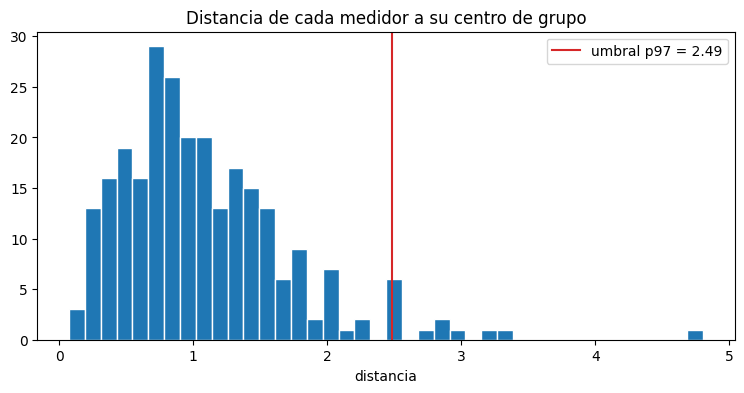

In [ ]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

+++++++\
En el eje horizontal (X) se representa la distancia al centroide. Cuanto mayor sea esta distancia, más diferente es el comportamiento del medidor respecto a su grupo.

En el eje vertical (Y) se representa la frecuencia, es decir, cuántos medidores presentan distancias dentro de cada intervalo.

La línea vertical roja indica el umbral de anomalía (percentil 97 = 2,49).

¿Qué observamos?
- Concentración principal: la mayoría de los medidores presenta distancias entre 0,3 y 1,6 aproximadamente. Esto indica que sus características son relativamente similares a las de los centroides de sus respectivos grupos.
- Disminución progresiva: a medida que aumenta la distancia, disminuye la cantidad de medidores. Los comportamientos más alejados son menos frecuentes.
- Medidores anómalos: a la derecha de la línea roja se encuentran los ocho medidores identificados como anómalos.
- Caso extremo: existe un medidor con distancia cercana a 4,8 (M00184), considerablemente más alejado que el resto.

El percentil 97 indica que aproximadamente el 97 % de los medidores tiene una distancia menor o igual a 2,49.

Por lo tanto:\
Clasificación - Condición	- Interpretación\
No anómalo	- Distancia ≤ 2,49	- Dentro del umbral establecido\
Anómalo -	Distancia > 2,49	- Comportamiento inusual respecto a su

**Importante:**\
Esto no significa que el 97 % de los medidores funcione correctamente. Solo significa que sus distancias no superan el umbral seleccionado.

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

++++++++\
Esto significa que se decidió revisar aproximadamente el 3 % de los medidores que presentan las mayores distancias respecto a sus centroides.

Pero se podría haber elegido otros percentiles:\
Percentil - Porcentaje superior	- Medidores aproximados\
90	- 10 %	- 26\
95	- 5 %	- 13\
97 -	3 %	 -8\
99 -	1 %	 -3

Los valores son aproximados; la cantidad exacta depende de las distancias y de posibles empates.

¿Cómo elegir el percentil?
Depende del problema que estás intentando resolver.

Caso A: poca capacidad de revisión

Supongamos que la distribuidora eléctrica solamente puede revisar tres medidores por semana.

Conviene utilizar un percentil más alto, por ejemplo el 99, para concentrarse en los casos más extremos.

Caso B: alto costo de no detectar una anomalía

Supongamos que un comportamiento anómalo podría anticipar una falla importante en el suministro eléctrico.

Podrías utilizar el percentil 90 para revisar más medidores y reducir el riesgo de omitir casos relevantes.

Sin embargo, revisar más casos también puede aumentar la cantidad de falsas alarmas.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [ ]:
# Tu código aquí: mira el detalle de esos medidores en el archivo original
# Obtener los tres medidores más anómalos
top3 = anomalos.sort_values(
    'distancia', ascending=False
).head(3)

# Mostrar sus perfiles
display(top3)

# Obtener los identificadores
ids = top3.index.tolist()

# Buscar sus registros originales
detalle = grande[
    grande['medidor_id'].isin(ids)
]

# Mostrar los registros
display(
    detalle.sort_values(['medidor_id', 'fecha_hora'])
)

,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.326759,1.882508,7.95315,0.649254,2,4.803416
M00074,3.851677,1.656171,6.98325,0.635850,2,3.319218
M00028,1.002319,0.446892,1.81920,0.610352,1,3.186759


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
28,M00028,2025-04-01 00:00:00,Talcahuano,BT1,0.309,3.1,0
288,M00028,2025-04-01 02:00:00,Talcahuano,BT1,0.578,7.9,2
548,M00028,2025-04-01 04:00:00,Talcahuano,BT1,0.444,9.7,4
808,M00028,2025-04-01 06:00:00,Talcahuano,BT1,0.989,9.7,6
1068,M00028,2025-04-01 08:00:00,Talcahuano,BT1,1.374,11.9,8
...,...,...,...,...,...,...,...
279684,M00184,2025-06-29 14:00:00,Los Ángeles,BT2,3.016,11.6,14
279944,M00184,2025-06-29 16:00:00,Los Ángeles,BT2,3.622,9.1,16
280204,M00184,2025-06-29 18:00:00,Los Ángeles,BT2,6.202,6.4,18
280464,M00184,2025-06-29 20:00:00,Los Ángeles,BT2,3.176,6.7,20


In [ ]:
resumen = detalle.groupby('medidor_id').agg(
    registros=('consumo_kwh', 'size'),
    minimo=('consumo_kwh', 'min'),
    maximo=('consumo_kwh', 'max'),
    promedio=('consumo_kwh', 'mean'),
    negativos=('consumo_kwh', lambda x: (x < 0).sum()),
    faltantes=('consumo_kwh', lambda x: x.isna().sum())
)

display(resumen.round(3))

,registros,minimo,maximo,promedio,negativos,faltantes
medidor_id,,,,,,
M00028,1080,0.309,2.758,1.002,0,0
M00074,1080,1.188,11.745,3.852,0,0
M00184,1080,1.267,11.628,4.327,0,0


Hay tres observaciones importantes:
- Completitud: los tres medidores tienen 1.080 registros y ninguno presenta valores faltantes.
- Valores negativos: no existen consumos negativos, lo que descarta ese tipo específico de inconsistencia.
- Variación: los tres presentan diferencias entre sus consumos mínimos y máximos, especialmente M00074 y M00184.

Sin embargo, que no existan negativos ni faltantes no garantiza que todos los valores sean correctos.

Diagnóstico de cada medidor\
M00184 — Fenómeno real probable
Es el medidor más anómalo, con una distancia de 4,803 al centroide.

Su consumo medio es de 4,327 kWh, con valores entre 1,267 y 11,628 kWh.

Presenta un consumo relativamente elevado y variable. No existen valores negativos ni faltantes que indiquen errores evidentes.

Decisión: conservar. Podría corresponder a un consumidor con alta demanda eléctrica, aunque debe verificarse su historial y tipo de cliente.\
M00074 — Fenómeno real probable
Presenta una distancia de 3,319 al centroide.

Su consumo medio es de 3,852 kWh y registra un máximo de 11,745 kWh, el mayor de los tres medidores.

El valor máximo es aproximadamente tres veces su promedio, lo que sugiere episodios de consumo elevado.

Decisión: conservar y revisar si los máximos corresponden a episodios aislados o a un patrón repetitivo. No hay evidencia suficiente para corregirlos.\
M00028 — Fenómeno real probable
Presenta una distancia de 3,187 al centroide, aunque su consumo medio es de apenas 1,002 kWh.

Sus registros varían entre 0,309 y 2,758 kWh.

Esto demuestra que un medidor puede ser anómalo sin presentar un consumo elevado en términos absolutos. Su anomalía se relaciona con la distancia respecto al comportamiento típico del grupo 1.

Decisión: conservar. No se observan inconsistencias evidentes en el resumen.



### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

Dimensiones: (720, 12)


,pm25_medio,pm10_medio,temperatura_media,humedad_media
estacion,,,,
CORONEL NORTE,47.43,88.47,11.03,75.26
COYHANCO,72.55,125.38,10.91,76.55
KINGSTON,50.98,81.58,11.23,76.21
LOS ANGELES ORIENTE,78.56,113.66,11.33,75.43
OSORNO ENTRE LAGOS,67.20,112.19,11.15,76.47
TALCAHUANO,43.90,72.11,10.85,75.91
TEMUCO PADRE LAS CASAS,81.11,138.10,10.97,75.21
VALDIVIA CENTRO,58.78,104.44,10.79,76.10


,k,silueta
0,2,0.242656
1,3,0.267986
2,4,0.175774
3,5,0.115997


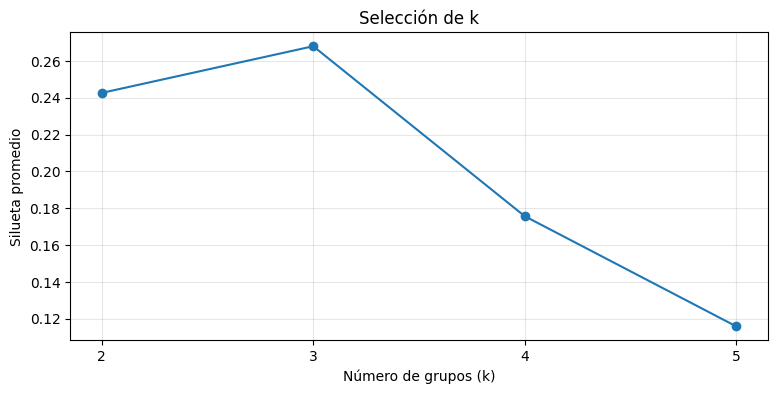

Número de grupos elegido: 3


,pm25_medio,pm10_medio,temperatura_media,humedad_media,grupo
estacion,,,,,
COYHANCO,72.55,125.38,10.91,76.55,0
OSORNO ENTRE LAGOS,67.20,112.19,11.15,76.47,0
VALDIVIA CENTRO,58.78,104.44,10.79,76.10,0
CORONEL NORTE,47.43,88.47,11.03,75.26,1
TALCAHUANO,43.90,72.11,10.85,75.91,1
KINGSTON,50.98,81.58,11.23,76.21,1
LOS ANGELES ORIENTE,78.56,113.66,11.33,75.43,2
TEMUCO PADRE LAS CASAS,81.11,138.10,10.97,75.21,2


,estaciones,pm25,pm10,temperatura,humedad
grupo,,,,,
0,3,66.18,114.00,10.95,76.37
1,3,47.44,80.72,11.04,75.79
2,2,79.84,125.88,11.15,75.32


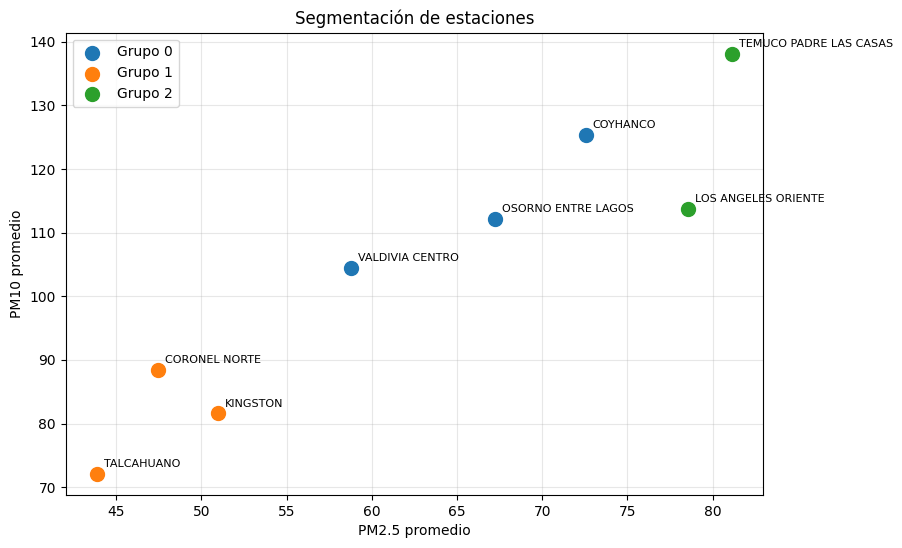

Tres estaciones más extremas:


,pm25_medio,pm10_medio,temperatura_media,humedad_media,grupo,distancia
estacion,,,,,,
KINGSTON,50.983,81.581,11.232,76.210,1,1.405
VALDIVIA CENTRO,58.777,104.436,10.787,76.097,0,1.276
LOS ANGELES ORIENTE,78.563,113.659,11.334,75.430,2,1.191


In [ ]:
# Tu código aquí

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Cargar datos
mio = pd.read_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';')

print('Dimensiones:', mio.shape)

# 2. Construir perfiles por estación
perfil2 = mio.groupby('estacion').agg(
    pm25_medio=('pm25', 'mean'),
    pm10_medio=('pm10', 'mean'),
    temperatura_media=('temperatura_c', 'mean'),
    humedad_media=('humedad_pct', 'mean')
)

perfil2 = perfil2.dropna()
display(perfil2.round(2))

# 3. Estandarizar
escalador = StandardScaler()
X = escalador.fit_transform(perfil2)

# 4. Evaluar distintos valores de k
resultados = []

for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X)

    silueta = silhouette_score(X, etiquetas)
    resultados.append((k, silueta))

evaluacion = pd.DataFrame(
    resultados, columns=['k', 'silueta']
)

display(evaluacion)

# 5. Graficar siluetas
plt.plot(evaluacion['k'], evaluacion['silueta'], marker='o')
plt.xlabel('Número de grupos (k)')
plt.ylabel('Silueta promedio')
plt.title('Selección de k')
plt.xticks(evaluacion['k'])
plt.grid(alpha=0.3)
plt.show()

# 6. Elegir el mejor k
mejor_k = int(
    evaluacion.loc[evaluacion['silueta'].idxmax(), 'k']
)

km = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=10
)

perfil2['grupo'] = km.fit_predict(X)

print('Número de grupos elegido:', mejor_k)
display(perfil2.sort_values('grupo').round(2))

# 7. Caracterizar grupos
resumen = perfil2.groupby('grupo').agg(
    estaciones=('pm25_medio', 'size'),
    pm25=('pm25_medio', 'mean'),
    pm10=('pm10_medio', 'mean'),
    temperatura=('temperatura_media', 'mean'),
    humedad=('humedad_media', 'mean')
)

display(resumen.round(2))

# 8. Visualizar grupos
plt.figure(figsize=(9, 6))

for grupo in sorted(perfil2['grupo'].unique()):
    datos = perfil2[perfil2['grupo'] == grupo]

    plt.scatter(
        datos['pm25_medio'],
        datos['pm10_medio'],
        s=100,
        label=f'Grupo {grupo}'
    )

    for estacion, fila in datos.iterrows():
        plt.annotate(
            estacion,
            (fila['pm25_medio'], fila['pm10_medio']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

plt.xlabel('PM2.5 promedio')
plt.ylabel('PM10 promedio')
plt.title('Segmentación de estaciones')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 9. Detectar estaciones atípicas
distancias = np.linalg.norm(
    X - km.cluster_centers_[km.labels_],
    axis=1
)

perfil2['distancia'] = distancias

# Tres estaciones más alejadas de su centro
extremas = perfil2.nlargest(3, 'distancia')

print('Tres estaciones más extremas:')
display(extremas.round(3))


Según los resultados obtenidos con K-means, las tres estaciones más alejadas de los centroides de sus respectivos grupos son:\
Estación	- Grupo	- Distancia	- Tipo de contaminación del grupo\
Kingston -	1	- 1,405	- Baja relativa\
Valdivia Centro	- 0	 - 1,276	- Intermedia\
Los Ángeles Oriente -	2 -	1,191 -	Elevada\


El algoritmo identificó 3 grupos de estaciones de monitoreo, diferenciados principalmente por sus niveles promedio de contaminación PM2.5 y PM10.\
Grupo -	Estaciones -	PM2.5 -	PM10	- Nombre propuesto\
0	     - 3	       -   66,18	 -    114,00 - 	Contaminación intermedia\
1	    -  3	        - 47,44	   - 80,72	-  Contaminación baja relativa\
2	   -  2	   -      79,84	 -   125,88	- Contaminación elevada\

1. Kingston — Mayor distancia (1,405)
Pertenece al grupo 1, caracterizado por una contaminación relativamente baja. Sus valores de PM2.5 (50,983) y PM10 (81,581) son cercanos a los promedios de su grupo.

Por lo tanto, su distancia elevada podría explicarse principalmente por las variables meteorológicas o por la combinación de los cuatro atributos.\
2. Valdivia Centro — Segunda mayor distancia (1,276)
Pertenece al grupo 0, de contaminación intermedia. Presenta valores de PM2.5 (58,777) y PM10 (104,436), inferiores a los promedios de su grupo (66,18 y 114,00).

Esto indica que tiene un perfil de contaminación relativamente menor que el resto de su grupo.\
3. Los Ángeles Oriente — Tercera mayor distancia (1,191)
Pertenece al grupo 2, caracterizado por contaminación elevada.

Presenta PM2.5 de 78,563 y PM10 de 113,659. Este último es inferior al promedio de su grupo (125,88).

Su comportamiento es diferente al centroide del grupo, aunque mantiene niveles elevados de material particulado.

Conclusión:\
Las tres estaciones presentan diferencias respecto de los perfiles de sus grupos. Sin embargo, no se puede afirmar que sean errores de medición o anomalías reales sin revisar sus registros originales.

La distancia al centroide permite identificar casos que requieren mayor análisis, pero no determina por sí sola la causa de su comportamiento.


---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

+++++\
Esta actividad busca comprobar si un modelo de aprendizaje automático (Machine Learning) realmente aprende una relación entre las variables o si simplemente encuentra patrones que no sirven para predecir nuevos datos.

La idea es utilizar los perfiles de consumo eléctrico  construidos antes y comparar dos problemas de predicción.

¿Qué queremos predecir?\
Modelo	- Variables predictoras (X) - 	Variable objetivo (y)\
Modelo 1	- Consumo medio, variabilidad y razón nocturna -	Punta de consumo (percentil 95)\
Modelo 2	 - Consumo medio, variabilidad y punta	-  Razón nocturna

Ambos modelos utilizan los mismos registros y el mismo algoritmo. Lo único que cambia es la variable que intentamos predecir.

**R² (coeficiente de determinació) será la métrica que permitirá evaluar qué tan bien un modelo de regresión predice una variable numérica)**

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor

def comparar(y, columnas, titulo):
    Xv = perfil[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar(perfil['punta'],
         ['consumo_medio', 'variabilidad', 'razon_nocturna'],
         'A · Predecir la PUNTA de consumo')
comparar(perfil['razon_nocturna'],
         ['consumo_medio', 'variabilidad', 'punta'],
         'B · Predecir la RAZÓN NOCTURNA')

A · Predecir la PUNTA de consumo
 profundidad   R² train    R² test
           2      0.892      0.853
           4      0.994      0.984
           8      1.000      0.997
          16      1.000      0.992
        None      1.000      0.992

B · Predecir la RAZÓN NOCTURNA
 profundidad   R² train    R² test
           2      0.060     -0.078
           4      0.182     -0.070
           8      0.569     -0.280
          16      0.970     -0.890
        None      1.000     -0.919



### Lo que muestran las dos tablas

**Caso A — hay relación.** El R² de entrenamiento sube a 1,00 y el de prueba lo acompaña, quedándose en torno a 0,99. El modelo aprendió algo que también vale fuera de los datos con que aprendió.

**Caso B — no hay relación.** Mira la columna de la derecha: el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,9 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a **1,000**: perfecto.

> **Un R² negativo significa que el modelo predice peor que decir siempre el promedio.** Y aun así, sobre los datos de entrenamiento acierta todo. Eso es exactamente el sobreajuste: el árbol no encontró un patrón, **memorizó las filas**.

La lección práctica: si alguien te presenta un modelo con 98 % de acierto y no te dice sobre qué datos se midió, la cifra no significa nada. Un modelo siempre puede memorizar sus propios datos.

++++++++++\
Explicación de los dos casos: relación y sobreajuste\
El objetivo de esta comparación es demostrar que un modelo de árbol de decisión puede obtener resultados perfectos durante el entrenamiento y, aun así, ser incapaz de predecir correctamente nuevos datos.

**Caso A:** Existe una relación entre las variables
- R² de entrenamiento ≈ 1,00: el árbol de decisión aprende muy bien los datos utilizados para entrenarlo.
- R² de prueba ≈ 0,99: el modelo también predice correctamente datos que nunca había visto.

Conclusión: existe una relación que el modelo puede aprovechar para generalizar.
En este caso, aumentar la profundidad del árbol permite aprender relaciones más complejas sin perjudicar significativamente el rendimiento sobre los datos de prueba.\

**Caso B:** No existe una relación predictiva aprovechable
- R² de entrenamiento = 1,00: el árbol consigue reproducir perfectamente los valores de entrenamiento.
- R² de prueba ≈ −0,90: el modelo realiza predicciones muy deficientes sobre datos nuevos.\
Conclusión: el árbol está memorizando los datos en lugar de aprender una relación generalizable.
A medida que aumenta la profundidad del árbol, el entrenamiento mejora, pero la predicción sobre nuevos datos empeora.\
Esto es un ejemplo de sobreajuste (overfitting).

¿Por qué ocurre esto?
Un árbol de decisión muy profundo puede generar tantas divisiones que termina identificando individualmente los registros de entrenamiento.

¿Qué significa un R² negativo?
Un R² negativo significa que el modelo predice peor que una estrategia sencilla: utilizar siempre el promedio de la variable objetivo calculado con los datos de entrenamiento.

Por ejemplo, si queremos predecir la razón nocturna:
- Predecir siempre el promedio podría producir un R² cercano a 0.
- Utilizar un árbol sobreajustado podría producir un R² de −0,90.
Por lo tanto, un modelo más complejo no necesariamente es un modelo mejor.
Relación con la actividad de los medidores eléctricos
En el ejercicio anterior:
- Predicción de la punta de consumo: podría corresponder al caso A, porque existen relaciones entre el consumo medio, la variabilidad y la punta.
- Predicción de la razón nocturna: podría corresponder al caso B, porque las estadísticas generales del consumo no necesariamente permiten conocer cuándo se consume la energía.
Esto debe confirmarse con los resultados de prueba, no suponerse de antemano.

La enseñanza principal: un R² de entrenamiento igual a 1,00 no demuestra que el modelo sea bueno. Lo importante es su capacidad para predecir datos nuevos.

**En términos de ciencia de datos, memorizar no es lo mismo que aprender.**

### 4.2 Validación cruzada

Una sola partición puede tocarte fácil o difícil por azar. La validación cruzada parte los datos en k pliegues, entrena k veces y promedia. Lo valioso no es solo la media: es la **desviación**, que dice cuán estable es el resultado.

In [ ]:
for etiqueta, y, cols in [
    ('A · punta         ', perfil['punta'],          ['consumo_medio', 'variabilidad', 'razon_nocturna']),
    ('B · razón nocturna', perfil['razon_nocturna'], ['consumo_medio', 'variabilidad', 'punta']),
]:
    for prof in (2, None):
        s = cross_val_score(DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA),
                            perfil[cols], y, cv=5, scoring='r2')
        print(f'{etiqueta}  prof={str(prof):>4s}  R² = {s.mean():7.3f} ± {s.std():.3f}   '
              f'pliegues {np.round(s, 2)}')

A · punta           prof=   2  R² =   0.849 ± 0.019   pliegues [0.82 0.87 0.87 0.83 0.85]
A · punta           prof=None  R² =   0.994 ± 0.003   pliegues [1.   1.   0.99 0.99 0.99]
B · razón nocturna  prof=   2  R² =  -0.104 ± 0.056   pliegues [-0.08 -0.19 -0.03 -0.07 -0.15]
B · razón nocturna  prof=None  R² =  -0.830 ± 0.250   pliegues [-0.35 -0.95 -0.9  -1.08 -0.86]


Dos lecturas:

- El caso A con profundidad ilimitada entrega **0,994 ± 0,003**: estable en los cinco pliegues.
- El caso B con profundidad ilimitada entrega algo como **−0,83 ± 0,25**. No solo es malo: es **inestable**. Según qué pliegue te toque, el resultado cambia mucho.

> **Reporta siempre media y desviación.** Un 0,80 ± 0,03 y un 0,80 ± 0,25 son resultados muy distintos, y el segundo no sostiene ninguna decisión.

+++++\
**Interpretación**:\
En el **caso A** el modelo predice muy bien la punta de consumo y mantiene resultados estables entre las cinco particiones (pliegues). Esto sugiere que existe una relación predictiva fuerte entre el consumo medio, la variabilidad, la razón nocturna y la punta de consumo.\
En el **caso B** el modelo no consigue predecir adecuadamente la razón nocturna.
Al aumentar la complejidad del árbol, los resultados empeoran y se vuelven menos estables.
Esto es compatible con un problema de sobreajuste: el modelo aprende particularidades de los registros de entrenamiento que no se mantienen en los datos de prueba.

Usar 5 pliegues significa que los datos se dividen en cinco partes. En cada iteración, el modelo se entrena con cuatro partes y se evalúa con la restante.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

++++++\
Esta actividad busca responder una pregunta:

¿Si repetimos K-means con diferentes muestras de los medidores, obtenemos agrupamientos de calidad similar?

Un agrupamiento puede parecer bueno con una muestra determinada, pero cambiar considerablemente cuando utilizamos otros registros.

Por eso, se repetirá K-means 20 veces, utilizando cada vez una submuestra aleatoria del 80 % de los datos.

In [ ]:
siluetas = []
for i in range(20):
    idx = np.random.RandomState(SEMILLA + i).choice(len(X), int(len(X) * 0.8), replace=False)
    km_i = KMeans(n_clusters=3, random_state=SEMILLA + i, n_init=10).fit(X[idx])
    siluetas.append(silhouette_score(X[idx], km_i.labels_))

siluetas = np.array(siluetas)
print(f'Silueta sobre 20 submuestras del 80 %: {siluetas.mean():.3f} ± {siluetas.std():.3f}')
print(f'Rango: [{siluetas.min():.3f}, {siluetas.max():.3f}]')

Silueta sobre 20 submuestras del 80 %: 0.231 ± 0.042
Rango: [0.148, 0.297]


+++++Α realizar 20 segmentaciones con K-means utilizando submuestras aleatorias del 80 % de los medidores, se obtuvo una silueta promedio de 0,231 y una desviación estándar de 0,042.

Estos resultados indican que la separación entre los tres grupos es relativamente débil, aunque la calidad del agrupamiento presenta variaciones moderadas entre las distintas muestras.

Se concluye que la calidad de la segmentación es relativamente consistente, pero los grupos no están claramente diferenciados. Para confirmar que la estructura de agrupamiento es estable, sería necesario comparar también las asignaciones de los medidores entre las distintas ejecuciones.

### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

++++++\
Se utiliza el hallazgo obtenido con K-means al segmentar los medidores eléctricos en tres grupos.

El hallazgo principal podría formularse como:\
**Los medidores eléctricos pueden agruparse en tres perfiles de consumo según su consumo medio, variabilidad, punta de consumo y razón nocturna.**

La pregunta es si esos tres grupos se mantienen al cambiar la muestra de medidores.

Como ya se realizaron 20 submuestras del 80 % en el ejercicio 4.3. Se reutilizan esos resultados:

In [ ]:
# Tu código aquí
print("Hallazgo: segmentación en 3 grupos")

print(f"Silueta media: {siluetas.mean():.3f}")
print(f"Desviación: {siluetas.std():.3f}")
print(f"Valor mínimo: {siluetas.min():.3f}")
print(f"Valor máximo: {siluetas.max():.3f}")

Hallazgo: segmentación en 3 grupos
Silueta media: 0.231
Desviación: 0.042
Valor mínimo: 0.148
Valor máximo: 0.297


_Tu estimación de robustez y tu conclusión:_\
Hallazgo principal: Los medidores eléctricos presentan características de consumo que permiten segmentarlos en tres grupos mediante K-means.

Estimación de robustez: Se realizaron 20 segmentaciones utilizando submuestras aleatorias del 80 % de los medidores. Se obtuvo una silueta media de 0,231, con una desviación estándar de 0,042 y valores entre 0,148 y 0,297.

Conclusión: Los resultados muestran que la calidad de la segmentación es relativamente consistente entre las distintas submuestras. Sin embargo, la silueta media es baja, lo que indica que los grupos no están claramente separados.

Por lo tanto, el hallazgo solo sugiere una hipótesis y todavía no es suficientemente sólido para fundamentar una decisión operativa. Se requiere comprobar la estabilidad de las asignaciones y analizar mejor las características de los grupos antes de utilizarlos para tomar decisiones.

¿Qué faltaría para sostener una decisión?\
Por ejemplo, si la empresa eléctrica quisiera diseñar tarifas diferentes para los tres grupos, los resultados actuales serían insuficientes.

En cambio, sí podrían justificar una investigación adicional sobre los perfiles de consumo.

La diferencia fundamental es que encontrar grupos no significa automáticamente que esos grupos sean suficientemente claros, estables y útiles para tomar decisiones.

---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [ ]:
import os, time

ruta = RUTA + 'S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

Tamaño en disco: 13.2 MB


### Estrategia A · leer todo

In [ ]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Tiempo: 0.25 s · Memoria: 68.0 MB · Filas: 280,800


Fíjate: **13 MB en disco se convierten en unos 68 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

++++++\
¿Por qué aumenta tanto el tamaño?
Porque un archivo CSV guarda principalmente caracteres de texto, mientras que pandas debe transformar esos caracteres en estructuras de datos que permitan realizar cálculos y consultas.

Por ejemplo:
- medidor_id: identificadores almacenados como texto.
- comuna: nombres de comunas repetidos en muchas filas.
- tarifa: categorías de tarifas almacenadas como cadenas.
Las columnas de texto suelen consumir bastante memoria cuando pandas utiliza objetos de Python.

### Estrategia B · leer solo las columnas necesarias

In [ ]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

Tiempo: 0.19 s · Memoria: 16.9 MB
Reducción de memoria: 75 %


++++++\
En esta ejecución, la lectura pasó de 0,30 a 0,21 segundos, una reducción del 30 %.

Esto puede ocurrir porque pandas debe convertir y almacenar menos columnas.

Sin embargo, no significa que siempre será un 30 % más rápido. El tiempo depende del equipo, del archivo y de las condiciones de ejecución. Para comparar con mayor precisión, conviene repetir las mediciones.

### Estrategia C · procesar por bloques

In [ ]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

Tiempo: 0.29 s · Memoria máxima: la de UN bloque, no la del archivo
Medidores agregados: 260


+++++\
En este ejemplo, pandas procesa bloques de 50.000 filas, calcula estadísticas parciales y después combina los resultados.
Esta estrategia permite procesar grandes conjuntos de datos sin cargarlos completamente en memoria RAM. En este caso, el archivo se procesó en seis bloques y se obtuvieron estadísticas para 260 medidores en 0,30 segundos.

In [ ]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

¿Mismo resultado? True


++++++\
El objetivo de este código fue verificar que procesar el archivo completo y procesarlo por bloques produce exactamente los mismos resultados.

Esto significa que las sumas de consumo calculadas mediante el procesamiento por bloques coinciden, dentro de la tolerancia numérica, con las obtenidas al procesar el archivo completo.

Por lo tanto, el procesamiento por bloques no ha provocado diferencias significativas en las sumas de consumo de los medidores.

### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [ ]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

A · todo el archivo :  0.25 s ·   68.0 MB
B · dos columnas    :  0.19 s ·   16.9 MB
C · por bloques     :  0.29 s · memoria acotada al bloque


+++++\
La idea fundamental es distinguir entre optimizar el rendimiento y superar una limitación de recursos:
- Optimizar: hacer un trabajo utilizando menos tiempo o recursos.
- Habilitar: permitir realizar un trabajo que, por falta de recursos, no sería posible de otra manera.
En ciencia de datos, la mejor herramienta no siempre es la más compleja, sino la que resuelve el problema con los recursos disponibles.

### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

_Tu respuesta:_
1. **¿A partir de qué tamaño de archivo cambiarías de estrategia y por qué?**

Considerando que Google Colab dispone de aproximadamente 12 GB de RAM, comenzaría a evaluar el procesamiento por bloques cuando el archivo CSV alcance entre 1 y 2 GB, dependiendo de los tipos de datos y las columnas necesarias.

En el experimento, un archivo de 13,2 MB ocupó 68 MB en memoria, aproximadamente 5 veces más. Si esa proporción se mantuviera, un archivo de 2 GB podría necesitar alrededor de 10 GB de RAM, dejando poco espacio para otras operaciones.

Primero intentaría reducir la memoria utilizando usecols para cargar solamente las columnas necesarias. Si el archivo sigue siendo demasiado grande, utilizaría chunksize para procesarlo por bloques.

2. **Si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?**

Primero identificaría las columnas necesarias: comuna y consumo_kwh.

Después utilizaría pd.read_csv() con usecols para seleccionar esas dos columnas y chunksize para leer el archivo en bloques de 50.000 o 100.000 filas.

En cada bloque agruparía los registros por comuna y calcularía la suma de los consumos y la cantidad de registros válidos.

Luego acumularía las sumas y cantidades de cada comuna entre todos los bloques.

Finalmente, calcularía el consumo promedio de cada comuna dividiendo su consumo total por la cantidad total de registros válidos.

De esta manera podría analizar un archivo de 40 GB sin cargarlo completamente en memoria RAM y obtener resultados equivalentes a los del procesamiento completo.


---
## Cierre y versionado

In [ ]:
mio.to_csv(RUTA + 'mi_conjunto_minado.csv', sep=';', index=False)
print('Guardado')

Guardado


In [ ]:
# En una terminal:
# git add S4_Notebook_Laboratorio_CDD.ipynb mi_conjunto_minado.csv
# git commit -m 'Semana 4: mineria, validacion y volumen'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de entregar

- [ ] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [ ] Los grupos obtenidos tienen nombre descriptivo, no número
- [ ] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [ ] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [ ] Comparación del costo computacional de dos estrategias, con cifras propias
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_